### Facial Expression Recognition — LBP + KNN

LBP histogram features + k-nearest neighbors classifier, trained on FER-2013.
LBP histogram code adapted from the course examples by J. J. García Cárdenas.

In [1]:
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
from skimage.feature import local_binary_pattern
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier

DATA_DIR = "../data"  # FER-2013 from Kaggle (msambare/fer2013), shared at the repo root

#### **Loading the dataset**

In [2]:
def load_split(split):
    """Read every image of data/<split>/<emotion>/ ; the label is the emotion name."""
    path = os.path.join(DATA_DIR, split)
    images, labels = [], []
    for emotion in sorted(os.listdir(path)):          # sorted: same order on every OS
        folder_path = os.path.join(path, emotion)
        for image in sorted(os.listdir(folder_path)):
            images.append(plt.imread(os.path.join(folder_path, image)))
            labels.append(emotion)
    return np.array(images), np.array(labels)

X_train, y_train = load_split("train")
X_test, y_test = load_split("test")

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
for emotion in sorted(set(y_train)):
    print(f"{emotion:>9}: {np.sum(y_train == emotion):5d} train | {np.sum(y_test == emotion):5d} test")

X_train shape: (28709, 48, 48)
X_test shape: (7178, 48, 48)
    angry:  3995 train |   958 test
  disgust:   436 train |   111 test
     fear:  4097 train |  1024 test
    happy:  7215 train |  1774 test
  neutral:  4965 train |  1233 test
      sad:  4830 train |  1247 test
 surprise:  3171 train |   831 test


#### **LBP calculation**

In [3]:
numpoints_lbp = 25
radius_lbp = 5
lbp_method = "uniform"

X_train_lbp = np.zeros(X_train.shape)
for i in range(X_train.shape[0]):
    X_train_lbp[i, :, :] = local_binary_pattern(X_train[i, :, :], numpoints_lbp, radius_lbp, method=lbp_method)

print(X_train_lbp.shape)
print("LBP codes range:", X_train_lbp.min(), "to", X_train_lbp.max())

(28709, 48, 48)
LBP codes range: 0.0 to 26.0


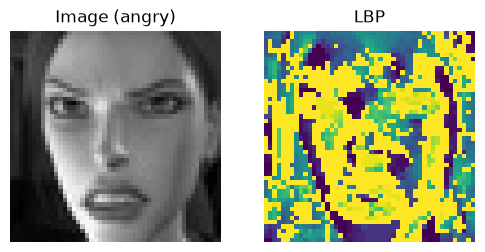

In [4]:
plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1)
plt.imshow(X_train[5], cmap="gray")
plt.title(f"Image ({y_train[5]})")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(X_train_lbp[5])
plt.title("LBP")
plt.axis("off")
plt.show()

#### **Region histograms**

The 48×48 LBP image is split into 4×4 regions; each region gives a histogram of the
P + 2 = 27 possible uniform codes. The 16 histograms are concatenated (16 × 27 = 432 features).

In [5]:
N = 4                       # 4x4 regions
n_bins = numpoints_lbp + 2  # "uniform" LBP gives codes 0..P+1


def NN_histogram(img_lbp, N, n_bins):
    """Histogram of the LBP codes in each of the N*N regions."""
    X_lbp_histNN_counts = np.zeros([N * N, n_bins])
    X_lbp_histNN_bins = np.zeros([N * N, n_bins + 1])
    for j in range(N * N):
        ii = np.floor(j / N)
        jj = j % N
        h1 = int(ii * (48 / N))
        h2 = int((ii + 1) * (48 / N))
        w1 = int(jj * (48 / N))
        w2 = int((jj + 1) * (48 / N))
        counts, bins = np.histogram(img_lbp[h1:h2, w1:w2].flatten(), bins=n_bins, range=(0, n_bins))
        X_lbp_histNN_counts[j, :] = counts
        X_lbp_histNN_bins[j, :] = bins
    return X_lbp_histNN_counts, X_lbp_histNN_bins

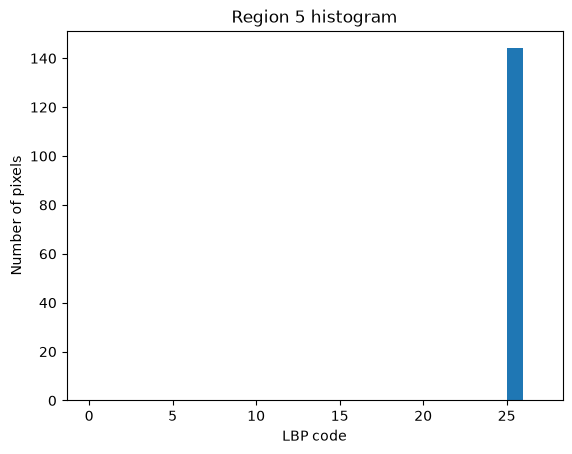

In [6]:
# Example: histogram of one region of one image
counts, bins = NN_histogram(X_train_lbp[2, :, :], N, n_bins)

region = 5
plt.hist(bins[region, :-1], bins[region], weights=counts[region])
plt.xlabel("LBP code")
plt.ylabel("Number of pixels")
plt.title(f"Region {region} histogram")
plt.show()

In [7]:
# Features of every training image, flattened: (28709, 16, 27) -> (28709, 432)
X_train_features = np.array([NN_histogram(X_train_lbp[i], N, n_bins)[0].flatten()
                             for i in range(X_train_lbp.shape[0])], dtype=np.uint8)
print(X_train_features.shape)

(28709, 432)


#### **Training the KNN**

In [8]:
neigh = KNeighborsClassifier(n_neighbors=5, weights="distance", p=2, metric="minkowski")
neigh.fit(X_train_features, y_train)
joblib.dump(neigh, "knn_model.pkl", compress=3)  # used by knn_model.py and the interface
print("Classes:", neigh.classes_)

Classes: ['angry' 'disgust' 'fear' 'happy' 'neutral' 'sad' 'surprise']


#### **Evaluation on the test set**

Test accuracy: 38.52%

              precision    recall  f1-score   support

       angry       0.33      0.32      0.33       958
     disgust       0.50      0.46      0.48       111
        fear       0.38      0.35      0.36      1024
       happy       0.41      0.48      0.44      1774
     neutral       0.33      0.32      0.33      1233
         sad       0.35      0.27      0.31      1247
    surprise       0.46      0.57      0.51       831

    accuracy                           0.39      7178
   macro avg       0.40      0.39      0.39      7178
weighted avg       0.38      0.39      0.38      7178



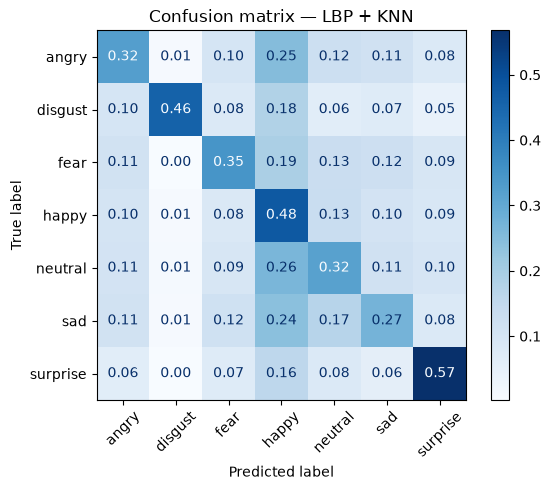

In [9]:
def features(img):
    img_lbp = local_binary_pattern(img, numpoints_lbp, radius_lbp, method=lbp_method)
    return NN_histogram(img_lbp, N, n_bins)[0].flatten()


X_test_features = np.array([features(img) for img in X_test], dtype=np.uint8)
y_pred = neigh.predict(X_test_features)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.2%}\n")
print(classification_report(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize="true", values_format=".2f",
                                        xticks_rotation=45, cmap="Blues")
plt.title("Confusion matrix — LBP + KNN")
plt.show()

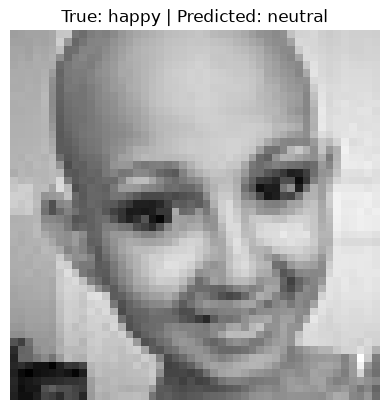

In [10]:
# Example: one test image with its prediction
rng = np.random.default_rng(0)
i = rng.choice(np.where(y_test == "happy")[0])

plt.imshow(X_test[i], cmap="gray")
plt.title(f"True: {y_test[i]} | Predicted: {y_pred[i]}")
plt.axis("off")
plt.show()